<a href="https://colab.research.google.com/github/vishnukumark77/CODESOFT_TASKS/blob/main/CODESOFT_TASKNO_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q transformers torch pillow



In [6]:
from transformers import BlipProcessor, BlipForConditionalGeneration
from PIL import Image
from google.colab import files
import matplotlib.pyplot as plt
import torch

# Load the pretrained image captioning model
model_name = "Salesforce/blip-image-captioning-base"

processor = BlipProcessor.from_pretrained(model_name)
model = BlipForConditionalGeneration.from_pretrained(model_name)

# Use GPU if available
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)

print("Image Captioning AI is ready!")

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

Image Captioning AI is ready!


Saving photo-1627764940620-90393d0e8c34.jpeg to photo-1627764940620-90393d0e8c34.jpeg


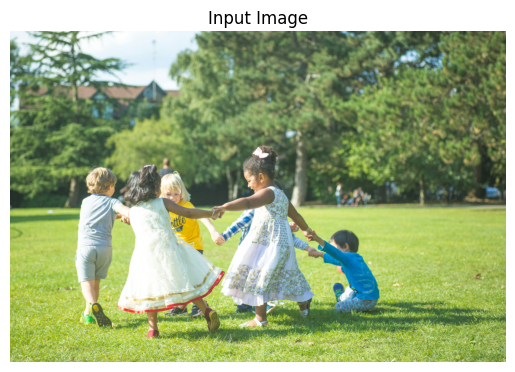

In [7]:
# Upload an image from your computer
uploaded = files.upload()

# Get the uploaded image filename
image_path = next(iter(uploaded))

# Open and convert image to RGB
image = Image.open(image_path).convert("RGB")

# Display the image
plt.imshow(image)
plt.axis("off")
plt.title("Input Image")
plt.show()

In [8]:
# Process the input image
inputs = processor(
    images=image,
    return_tensors="pt"
).to(device)

# Generate caption
with torch.no_grad():
    output = model.generate(
        **inputs,
        max_new_tokens=50
    )

# Convert generated tokens into text
caption = processor.decode(
    output[0],
    skip_special_tokens=True
)

print("Generated Caption:", caption)

Generated Caption: children playing in the park


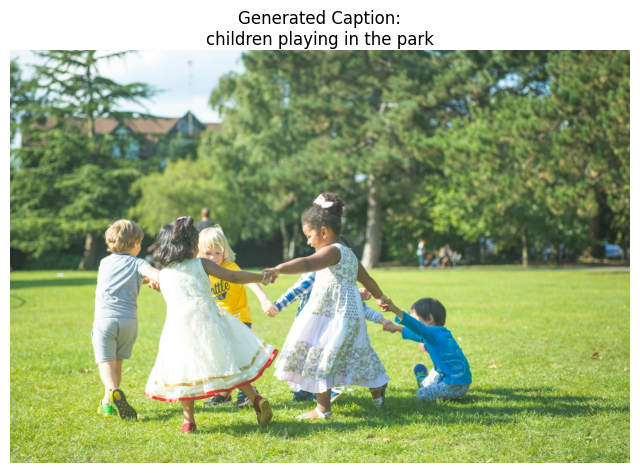

In [9]:
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Generated Caption:\n" + caption, wrap=True)
plt.show()